# K-Risk: DataFrame and visualization

Uses the per-event feature table shipped in `validation/results/` (HV events). The raw per-frame JSONs live on Figshare and are not in this repo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RES = Path("validation/results")
OUT = Path("report_figures"); OUT.mkdir(exist_ok=True)

_n = [0]
_show = plt.show
def _show_and_save(*a, **k):
    _n[0] += 1
    plt.gcf().savefig(OUT / f"fig{_n[0]}.png", dpi=200, bbox_inches="tight")
    _show(*a, **k)
plt.show = _show_and_save

df = pd.read_csv(RES / "event_features.csv", low_memory=False)
df["level"] = pd.Categorical(df["level"], ["moderate", "high", "extreme"], ordered=True)
print(df.shape)
df.head(10)

(30269, 50)


,event,src,level,sub,path,n_frames,n_agents,dur_s,drf_max,ttc_min_pos,ego_amax_raw,ego_amin_raw,ego_apos_raw,ego_amax_s,ego_amin_s,jerk,ego_acc_high,ego_brake_high,ego_yaw_left,ego_yaw_right,slot_amax_raw,slot_amax_s,slot_acc_high,slot_brake_high,slot_yaw_left,slot_yaw_right,n_flagged_slot_agents,flagged_roles,coll_rows_any,coll_agents_any,ego_is_partner,coll_slot_agents,coll_t_min_any,coll2s_frames,coll_t_min,n_coll_partners,coll_partner_in_slot_frac,peak_frame,min_clear,overlap_frames,overlap_partners,closest_in_slot,closest_cls,others_per_frame,slot_per_frame,nonslot_med_dist,nonslot_within20m_per_frame,vru_per_frame,pet,drac
0,expresswayA_track_10_car_4447_frame_377_to_470,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,94,6,3.100000,NaN,NaN,1.054935,-1.054935,0.727194,0.662641,-0.662641,2.692375,0.0,0.0,0.0,0.0,8.546082,5.651042,0.0,17.0,0.0,0.0,2.0,right_alongside|right_following,92.0,2.0,0.0,2.0,1.30,0.0,NaN,0.0,0.0,NaN,2.009730,0.0,0.0,1.0,car,5.000000,5.000000,NaN,0.0,0.0,NaN,0.314061
1,expresswayA_track_10_car_4447_frame_830_to_938,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,109,5,3.600000,NaN,7.33,5.606216,-5.198802,5.606216,3.400978,-3.400978,18.319967,9.0,11.0,0.0,0.0,2.877668,1.467303,0.0,0.0,0.0,0.0,0.0,NaN,2.0,2.0,0.0,2.0,2.00,0.0,NaN,0.0,0.0,NaN,1.116517,0.0,0.0,1.0,car,5.000000,5.000000,NaN,0.0,0.0,NaN,0.072998
2,expresswayA_track_13_car_2750_frame_3913_to_4006,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,94,5,3.100000,NaN,NaN,1.422280,-1.202184,1.422280,0.754141,-0.657472,3.067853,0.0,0.0,0.0,0.0,8.439401,36.422537,22.0,19.0,0.0,0.0,2.0,following|right_following,30.0,2.0,1.0,1.0,0.80,15.0,0.80,1.0,1.0,3929.0,0.236849,0.0,0.0,1.0,car,4.563830,4.563830,NaN,0.0,0.0,0.566667,0.000000
3,expresswayA_track_13_car_2994_frame_6234_to_6389,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,156,7,5.166667,NaN,9.56,3.424778,-1.665024,3.424778,2.224682,-1.191586,8.916779,5.0,0.0,1.0,0.0,11.750000,49.814468,27.0,8.0,33.0,5.0,3.0,following|left_alongside|left_following|left_p...,16.0,2.0,1.0,1.0,1.00,8.0,1.00,1.0,1.0,6274.0,0.777547,0.0,0.0,1.0,car,5.083333,5.083333,NaN,0.0,0.0,NaN,0.162460
4,expresswayA_track_13_car_3002_frame_6234_to_6325,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,92,8,3.033333,NaN,2.85,5.043003,-2.450055,5.043003,3.453554,-1.194130,12.249572,16.0,0.0,33.0,0.0,3.424778,2.224682,6.0,0.0,1.0,13.0,3.0,following|left_preceding|preceding|right_along...,16.0,2.0,1.0,1.0,1.00,8.0,1.00,1.0,1.0,6274.0,0.777547,0.0,0.0,1.0,car,6.239130,6.239130,NaN,0.0,0.0,2.133333,1.369459
5,expresswayA_track_15_car_4455_frame_801_to_907,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,107,5,3.533333,NaN,NaN,30.096345,-30.096345,2.851309,18.721752,-18.721752,48.095717,0.0,19.0,1.0,5.0,4.709417,3.883513,0.0,15.0,0.0,22.0,2.0,following|left_alongside|left_following|left_p...,40.0,2.0,1.0,1.0,0.05,20.0,0.05,1.0,1.0,899.0,0.148640,0.0,0.0,1.0,car,3.102804,3.102804,NaN,0.0,0.0,NaN,0.000000
6,expresswayA_track_16_car_453_frame_4236_to_4331,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,96,3,3.166667,NaN,54.18,7.187488,-3.962298,7.187488,3.259965,-1.770684,14.490822,9.0,9.0,0.0,0.0,3.587725,2.020333,0.0,2.0,0.0,0.0,1.0,left_following,10.0,2.0,1.0,1.0,0.80,5.0,0.80,1.0,1.0,4266.0,0.681441,0.0,0.0,1.0,car,2.479167,2.479167,NaN,0.0,0.0,2.833333,0.006949
7,expresswayA_track_16_car_459_frame_4236_to_4331,expresswayA,extreme,ttc_1s,event_annotations/HV/extreme/ttc_1s/expressway...,96,6,3.166667,NaN,NaN,2.932171,-1.949480,2.932171,1.979622,-0.562631,7.490434,0.0,0.0,0.0,0.0,8.327760,48.212213,9.0,11.0,0.0,0.0,2.0,following|right_alongside|right_preceding,10.0,2.0,1.0,1.0,0.80,5.0,0.80,1.0,1.0,4266.0,0.681441,0.0,0.0,1.0,car,4.479167,4.479167,NaN,0.0,0.0,0.900000,0.000000
8,expresswayA_track_17_car_1495_frame_5014_to_5123,expresswayA,ex

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30269 entries, 0 to 30268
Data columns (total 50 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   event                        30269 non-null  object  
 1   src                          30269 non-null  object  
 2   level                        30269 non-null  category
 3   sub                          1036 non-null   object  
 4   path                         30269 non-null  object  
 5   n_frames                     30269 non-null  int64   
 6   n_agents                     30269 non-null  int64   
 7   dur_s                        30269 non-null  float64 
 8   drf_max                      25031 non-null  float64 
 9   ttc_min_pos                  16200 non-null  float64 
 10  ego_amax_raw                 29544 non-null  float64 
 11  ego_amin_raw                 29544 non-null  float64 
 12  ego_apos_raw                 29544 non-null  float64 
 13  e

In [3]:
df[["n_frames", "n_agents", "dur_s", "drf_max", "ttc_min_pos", "min_clear"]].describe().T

,count,mean,std,min,25%,50%,75%,max
n_frames,30269.0,1.030670e+02,5.902102e+01,26.000000,67.000000,94.000000,126.000000,1.299000e+03
n_agents,30269.0,6.549605e+00,2.917927e+00,0.000000,4.000000,6.000000,8.000000,2.100000e+01
dur_s,30269.0,4.275198e+00,1.990800e+00,1.000000,3.000000,4.066667,5.000000,4.326667e+01
drf_max,25031.0,1.287177e+03,1.158968e+03,0.000000,406.953320,956.106082,1965.411936,4.529742e+04
ttc_min_pos,16200.0,1.546593e+13,8.287410e+14,0.000213,2.548995,9.260000,24.510000,7.096847e+16
min_clear,30268.0,3.999763e+00,8.589863e+00,0.000000,1.228168,1.776928,3.087552,2.741105e+02


## Composition: events per source and risk level

level,moderate,high,extreme,total
src,,,,
highd,7026,1781,0,8807
freewayB,3572,1008,724,5304
ind,4215,469,0,4684
expresswayA,2631,1576,312,4519
ngsim,1826,2376,0,4202
round,2477,276,0,2753


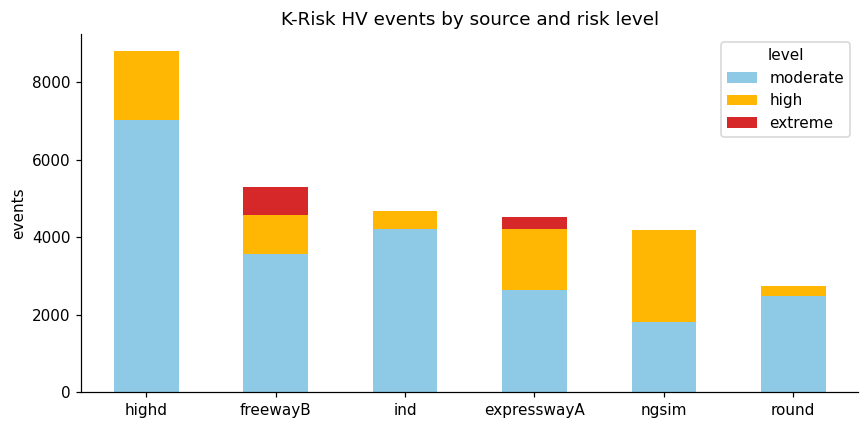

In [4]:
ct = pd.crosstab(df["src"], df["level"])
ct["total"] = ct.sum(axis=1)
ct = ct.sort_values("total", ascending=False)
display(ct)

colors = {"moderate": "#8ecae6", "high": "#ffb703", "extreme": "#d62828"}
ax = ct.drop(columns="total").plot.bar(stacked=True, color=[colors[c] for c in ct.columns[:-1]], figsize=(8, 4))
ax.set_ylabel("events"); ax.set_xlabel(""); ax.set_title("K-Risk HV events by source and risk level")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

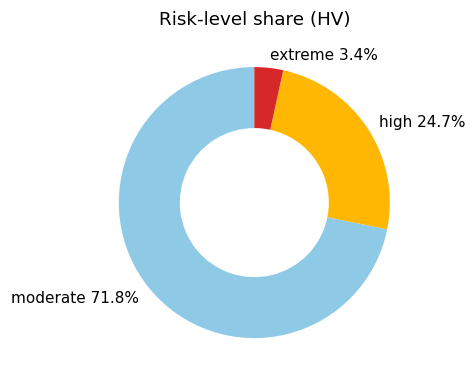

In [5]:
share = df["level"].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(4, 4))
ax.pie(share, labels=[f"{k} {v:.1f}%" for k, v in share.items()],
       colors=[colors[k] for k in share.index], startangle=90, wedgeprops={"width": 0.45})
ax.set_title("Risk-level share (HV)"); plt.show()

## Event properties

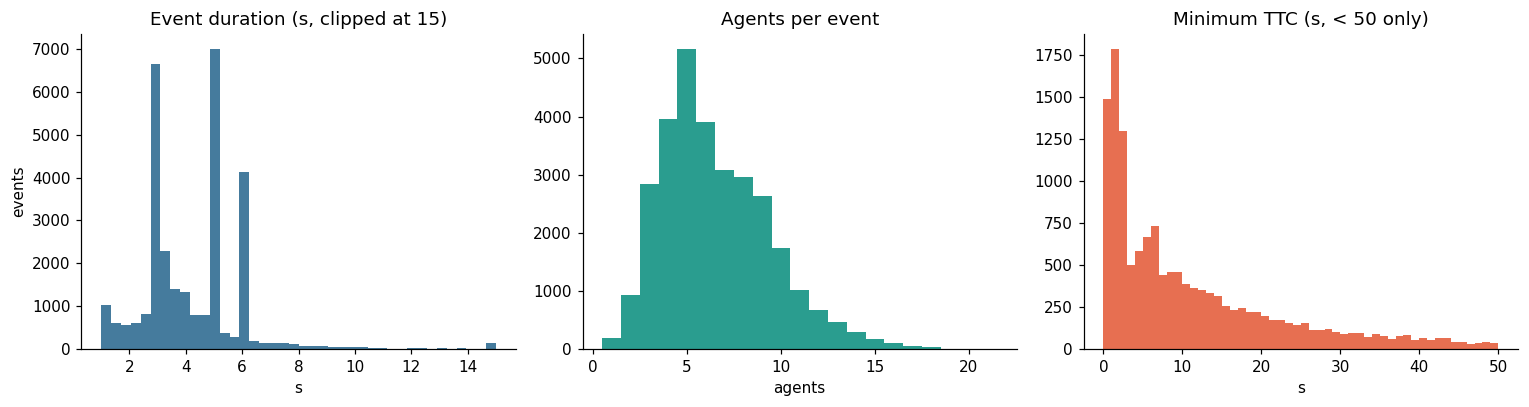

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].hist(df["dur_s"].clip(upper=15), bins=40, color="#457b9d")
axes[0].set(title="Event duration (s, clipped at 15)", xlabel="s", ylabel="events")

axes[1].hist(df["n_agents"], bins=np.arange(0.5, df["n_agents"].max() + 1.5), color="#2a9d8f")
axes[1].set(title="Agents per event", xlabel="agents")

ttc = df["ttc_min_pos"].where(df["ttc_min_pos"] < 50).dropna()
axes[2].hist(ttc, bins=50, color="#e76f51")
axes[2].set(title="Minimum TTC (s, < 50 only)", xlabel="s")
plt.tight_layout(); plt.show()

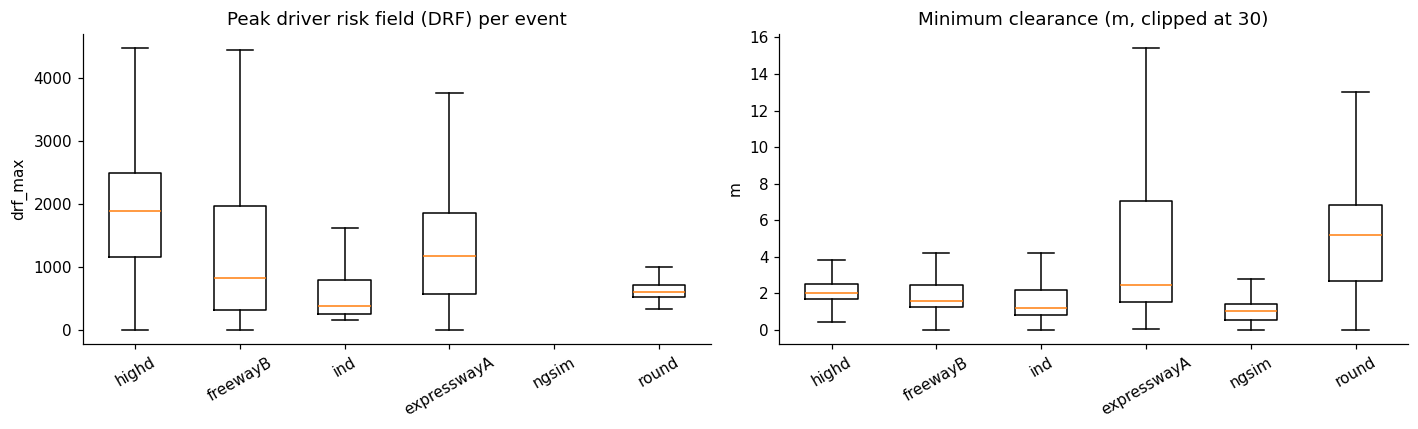

In [7]:
# Box plots per source (log-scale for the heavy-tailed DRF peak)
order = ct.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].boxplot([df.loc[df.src == s, "drf_max"].dropna() for s in order], tick_labels=order, showfliers=False)
axes[0].set(title="Peak driver risk field (DRF) per event", ylabel="drf_max")

axes[1].boxplot([df.loc[df.src == s, "min_clear"].dropna().clip(upper=30) for s in order], tick_labels=order, showfliers=False)
axes[1].set(title="Minimum clearance (m, clipped at 30)", ylabel="m")
for a in axes: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

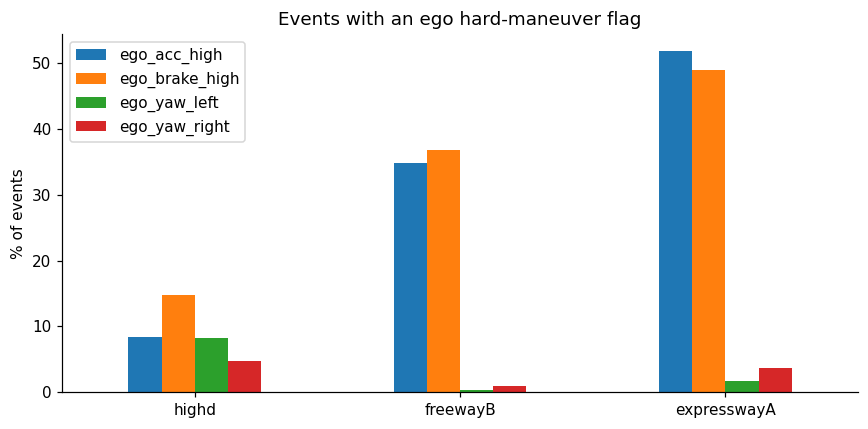

In [8]:
# Flag columns hold frame counts; an event is flagged if the count is > 0 (ind/round/ngsim have no flags)
flags = ["ego_acc_high", "ego_brake_high", "ego_yaw_left", "ego_yaw_right"]
has = df[flags].gt(0).where(df[flags].notna())
rate = has.groupby(df["src"]).mean().loc[["highd", "freewayB", "expresswayA"]] * 100
ax = rate.plot.bar(figsize=(8, 4))
ax.set(ylabel="% of events", xlabel="", title="Events with an ego hard-maneuver flag")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

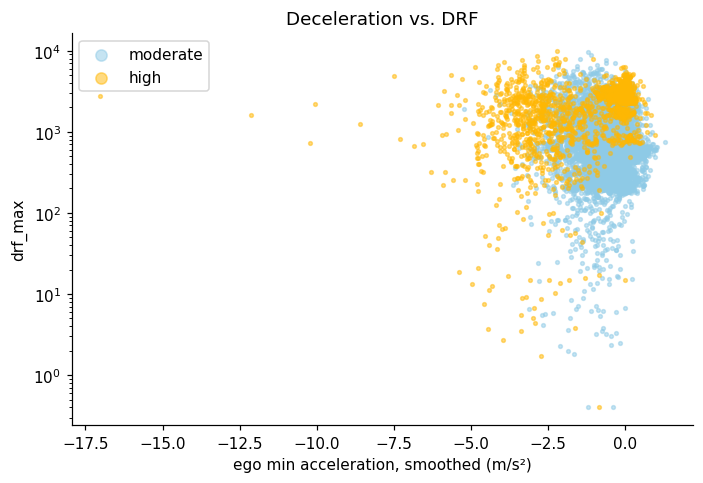

In [9]:
# Peak ego deceleration vs. peak DRF, colored by risk level
d = df.dropna(subset=["drf_max", "ego_amin_s"]).sample(8000, random_state=0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for lv, g in d.groupby("level", observed=True):
    ax.scatter(g["ego_amin_s"], g["drf_max"], s=6, alpha=.5, color=colors[lv], label=lv)
ax.set_yscale("log"); ax.set(xlabel="ego min acceleration, smoothed (m/s²)", ylabel="drf_max", title="Deceleration vs. DRF")
ax.legend(markerscale=3); plt.tight_layout(); plt.show()

## LLM-annotated subset (372 events)

In [10]:
llm = pd.read_csv(RES / "llm_audit_per_event.csv", low_memory=False)
print(llm.shape)
llm.head()

(372, 45)


,event,src,dir,n_neighbours,n_reminder_ids,ttc_warning,admissible,gpt4o_action,gpt4o_ar_n,gpt4o_ar_ok,gpt4o_op_n,gpt4o_op_ok,gpt4o_d_n,gpt4o_d_ok,gpt4o_flips,gpt4o_ttc_expr,gpt4o_ttc_operands_ok,gpt4o_ttc_arith_ok,gpt4o_ttc_dir_n,gpt4o_ttc_dir_ok,gpt4o_ttc_rule_flip,gpt4o_ids,gpt4o_ids_ok,gpt4o_rem_recall,gpt4o_admissible,gpt4o_legal,gpt41_action,gpt41_ar_n,gpt41_ar_ok,gpt41_op_n,gpt41_op_ok,gpt41_d_n,gpt41_d_ok,gpt41_flips,gpt41_ttc_expr,gpt41_ttc_operands_ok,gpt41_ttc_arith_ok,gpt41_ttc_dir_n,gpt41_ttc_dir_ok,gpt41_ttc_rule_flip,gpt41_ids,gpt41_ids_ok,gpt41_rem_recall,gpt41_admissible,gpt41_legal
0,expresswayA_track_10_car_4447_frame_377_to_470,expresswayA,east-west,3,0,0,145,4,6,6,4,4,2,0,1,0,0,0,0,0,0,3,3,NaN,1,1,1,2,2,2,2,2,2,0,0,0,0,0,0,0,3,3,NaN,1,1
1,expresswayA_track_10_car_4447_frame_830_to_938,expresswayA,east-west,5,0,0,145,1,10,10,8,8,4,4,0,0,0,0,0,0,0,5,5,NaN,1,1,1,10,10,8,8,4,4,0,0,0,0,0,0,0,5,5,NaN,1,1
2,expresswayA_track_10_car_4768_frame_377_to_470,expresswayA,east-west,5,1,1,5,5,2,2,0,0,2,2,0,0,0,0,0,0,0,5,5,1.0,1,1,5,4,4,4,4,1,1,0,0,0,0,0,0,0,5,5,1.0,1,1
3,expresswayA_track_13_car_2750_frame_3913_to_4006,expresswayA,east-west,2,1,0,1345,1,6,6,4,4,2,1,0,0,0,0,0,0,0,2,2,1.0,1,1,1,7,7,5,5,2,0,0,0,0,0,0,0,0,2,2,1.0,1,1
4,expresswayA_track_13_car_2994_frame_6234_to_6389,expresswayA,west-east,3,1,0,12345,1,8,8,6,6,3,2,0,0,0,0,0,0,0,3,3,1.0,1,1,1,7,7,6,6,3,3,0,0,0,0,0,0,0,3,3,1.0,1,1


In [11]:
fault = pd.read_csv(RES / "checker_fault.csv", low_memory=False)
print(fault.shape)
fault.head()

(372, 11)


,event,unsafe_IDLE,any_IDLE,unsafe_LEFT,any_LEFT,unsafe_RIGHT,any_RIGHT,unsafe_ACC,any_ACC,unsafe_DEC,any_DEC
0,expresswayA_track_10_car_4447_frame_377_to_470,0,0,1,1,0,0,1,1,0,0
1,expresswayA_track_10_car_4447_frame_830_to_938,0,0,1,1,1,1,0,0,0,0
2,expresswayA_track_10_car_4768_frame_377_to_470,1,1,1,1,1,1,1,1,0,1
3,expresswayA_track_13_car_2750_frame_3913_to_4006,0,0,1,1,0,0,0,0,0,0
4,expresswayA_track_13_car_2994_frame_6234_to_6389,0,0,0,0,0,0,0,0,0,0
